Load file zip của project

In [1]:
from google.colab import files

uploaded = files.upload()

Saving panorama-stitching-project.zip to panorama-stitching-project.zip


Giải nén

In [2]:
!unzip -q panorama-stitching-project.zip -d /content
%cd /content/panorama-stitching-project
!ls
!ls data

/content/panorama-stitching-project
data  Group08_Midterm.ipynb  out  README.md  src  testkeypoints.ipynb  tools
left.jpg  left.png  right.jpg  right.png


Biên dịch toàn bộ v0

In [3]:
!g++ -O2 -std=c++17 \
  -Isrc/core_headers \
  -Isrc/libraries \
  src/integration/main.cpp \
  src/integration/v0_pipeline.cpp \
  src/stage_implementations/v0_stage12.cpp \
  src/stage_implementations/v0_stage34.cpp \
  src/stage_implementations/v0_stage5.cpp \
  src/stage_implementations/v0_stage6.cpp \
  src/libraries/stb_impl.cpp \
  -o stitch

In [4]:
!ls -lh stitch

-rwxr-xr-x 1 root root 208K Oct 13 18:00 stitch


Chạy toàn bộ pipeline v0

In [5]:
!mkdir -p out

!./stitch \
  data/left.jpg \
  data/right.jpg \
  out/panorama_v0.jpg \
  --version 0 \
  --runs 5 \
  --debug-prefix out/debug_left_right

version=0 runs=5 imageA=1220x679 imageB=1220x685
keypoints_A=210 keypoints_B=40 matches=14 inliers=10
panorama=2097x679 inlier_ratio=0.714
avg_ms gray=4.205 blur=62.251 harris=88.736 nms_topk=4.011 describe=1.069 match=3.618 ransac=3.233 warp_blend=88.464 end_to_end=255.590


Kiểm tra output ảnh

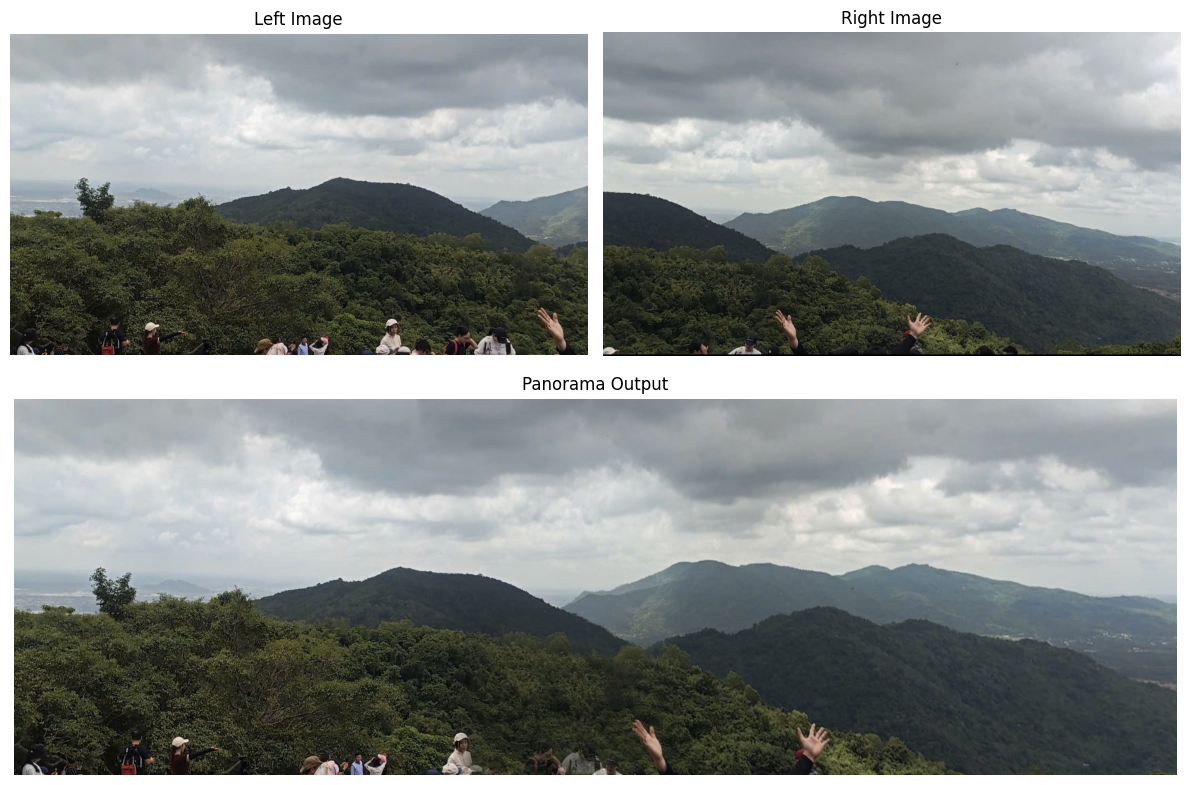

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

# 1. Load the images
left_img = Image.open("data/left.jpg")
right_img = Image.open("data/right.jpg")
out_img = Image.open("out/panorama_v0.jpg")

# 2. Create a figure with a specific size (width, height)
plt.figure(figsize=(12, 8))

# 3. Top-left image (2 rows, 2 columns, position 1)
plt.subplot(2, 2, 1)
plt.imshow(left_img)
plt.axis('off') # Hides the axes/gridlines
plt.title("Left Image")

# 4. Top-right image (2 rows, 2 columns, position 2)
plt.subplot(2, 2, 2)
plt.imshow(right_img)
plt.axis('off')
plt.title("Right Image")

# 5. Bottom image (2 rows, 1 column, position 2 - spans the whole bottom row)
plt.subplot(2, 1, 2)
plt.imshow(out_img)
plt.axis('off')
plt.title("Panorama Output")

# Adjusts spacing so titles and images don't overlap
plt.tight_layout()
plt.show()

self test s1 s2

In [7]:
!g++ -O2 -std=c++17 \
  -Isrc/core_headers \
  tools/run_stage12_selftest.cpp \
  src/integration/v0_selftest.cpp \
  src/stage_implementations/v0_stage12.cpp \
  -o stage12_selftest

!./stage12_selftest

[SELFTEST] constant image               PASS max_err=2.29e-05
[SELFTEST] impulse (sum, symmetry)      PASS sum=1000.000 asym=0.00e+00
[SELFTEST] separable == 2D blur         PASS max_err=2.87e-05
[SELFTEST] checkerboard corners         PASS worst_dist=2.0 missed_corners=0
[SELFTEST] determinism + ordering       PASS n=256
[SELFTEST] stage1-2 overall: ALL PASS


Kiểm tra synthetic homography S5

In [8]:
!g++ -O2 -std=c++17 \
  -Isrc/core_headers \
  tools/synthetic_homography_test.cpp \
  src/stage_implementations/v0_stage5.cpp \
  -o synthetic_homography_test

!./synthetic_homography_test

[SYNTHETIC_HOMOGRAPHY] PASS inliers=48 tx=37.000000 ty=-19.000000 tx_error=3.055e-13 ty_error=2.167e-13


Chạy timing ở ba độ phân giải

In [10]:
!g++ -O2 -std=c++17 \
  -Isrc/core_headers \
  -Isrc/libraries \
  tools/timing_stage12.cpp \
  src/stage_implementations/v0_stage12.cpp \
  src/libraries/stb_impl.cpp \
  -o timing_stage12

Chạy 5 lần, dùng cùng một cặp ảnh:

In [11]:
!./timing_stage12 5 data/left.jpg data/right.jpg

resolution=1280x720,runs=5,avg_ms_gray=5.697,avg_ms_blur=85.212,avg_ms_harris=114.351,avg_ms_nms_topk=4.754,keypoints_A=108,keypoints_B=100
resolution=1920x1080,runs=5,avg_ms_gray=11.700,avg_ms_blur=196.216,avg_ms_harris=243.514,avg_ms_nms_topk=9.969,keypoints_A=103,keypoints_B=103
resolution=3840x2160,runs=5,avg_ms_gray=32.787,avg_ms_blur=546.343,avg_ms_harris=723.047,avg_ms_nms_topk=35.994,keypoints_A=110,keypoints_B=112
